# Credit Card Fraud Detection — Imbalanced Classification

**Portfolio project:** exploratory data analysis, stratified split, baseline Logistic Regression, Logistic Regression + SMOTE, class-weighted Random Forest, confusion matrices, precision-recall curves, ROC curves, feature importance, and reproducible evaluation.

**Dataset:** [Kaggle ULB credit card fraud dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). 284,807 transactions, 492 fraud cases. `Class`: 0 = legitimate, 1 = fraud.

**Important:** SMOTE is applied to the *training fold only*, inside an `imblearn` pipeline. The test set is never resampled. Report metrics for the positive (fraud) class, especially recall, precision, F1 and average precision (AP).

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Imports and project paths

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, accuracy_score,
                             average_precision_score, roc_auc_score,
                             PrecisionRecallDisplay, RocCurveDisplay)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

sns.set_theme(style='whitegrid')
BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / 'creditcard.csv'
OUTPUT_DIR = BASE_DIR / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.exists(), f'Missing {DATA_PATH}; download creditcard.csv from Kaggle.' 

## 2. Load and validate the data

In [9]:
df = pd.read_csv(DATA_PATH)
assert 'Class' in df.columns
assert set(df['Class'].dropna().unique()) <= {0,1}
print('Shape:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
print('Class counts:')
print(df['Class'].value_counts().sort_index())
display(df.head())

Shape: (284807, 31)
Missing values: 0
Duplicate rows: 1081
Class counts:
Class
0    284315
1       492
Name: count, dtype: int64


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Exploratory data analysis

,Time,Amount,Class
count,284807.000000,284807.000000,284807.000000
mean,94813.859575,88.349619,0.001727
std,47488.145955,250.120109,0.041527
min,0.000000,0.000000,0.000000
25%,54201.500000,5.600000,0.000000
50%,84692.000000,22.000000,0.000000
75%,139320.500000,77.165000,0.000000
max,172792.000000,25691.160000,1.000000


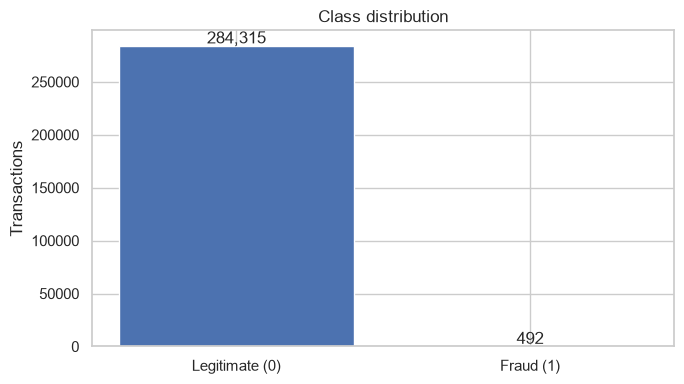

In [10]:
display(df[['Time','Amount','Class']].describe())
class_counts = df['Class'].value_counts().sort_index()
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(['Legitimate (0)','Fraud (1)'], class_counts.values)
ax.set(title='Class distribution', ylabel='Transactions')
for i,v in enumerate(class_counts.values): ax.text(i,v+2000,f'{v:,}',ha='center')
fig.tight_layout(); fig.savefig(OUTPUT_DIR/'01_class_distribution.png',dpi=150);plt.show()

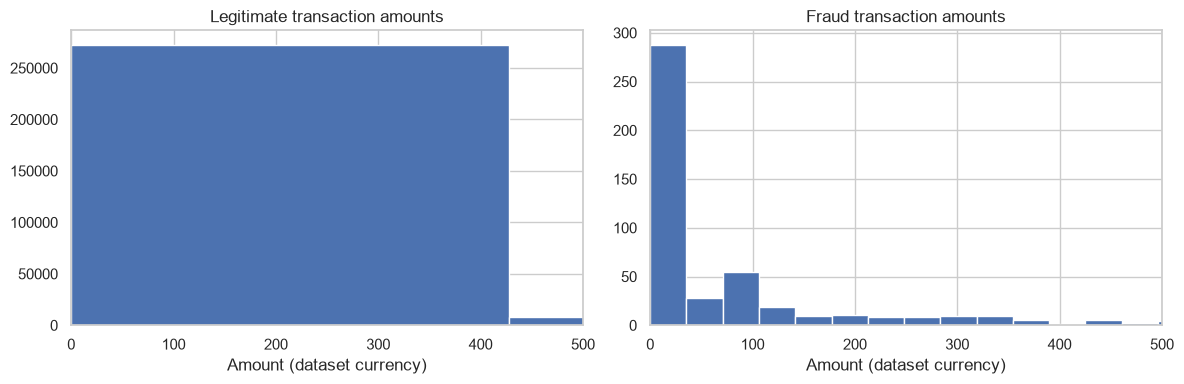

In [11]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,c in zip(axes,[0,1]):
    ax.hist(df.loc[df.Class==c,'Amount'],bins=60)
    ax.set(title=('Legitimate' if c==0 else 'Fraud')+' transaction amounts',xlabel='Amount (dataset currency)')
    ax.set_xlim(0,500)
fig.tight_layout();fig.savefig(OUTPUT_DIR/'02_amount_distribution.png',dpi=150);plt.show()

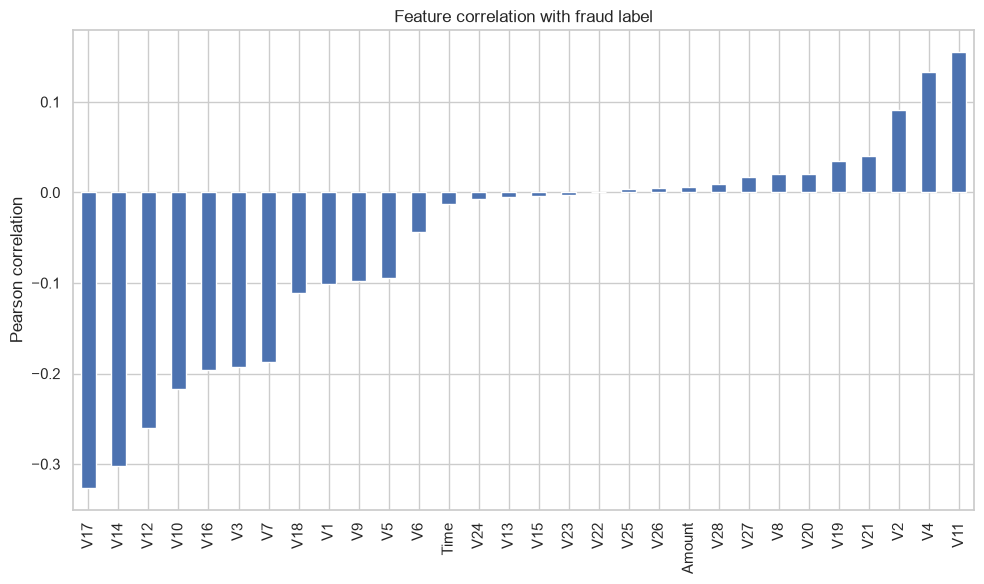

In [12]:
corr=df.corr(numeric_only=True)['Class'].drop('Class').sort_values()
fig,ax=plt.subplots(figsize=(10,6))
corr.plot(kind='bar',ax=ax)
ax.set(title='Feature correlation with fraud label',ylabel='Pearson correlation')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'03_feature_correlations.png',dpi=150);plt.show()

## 4. Train/test split — stratified to preserve rare fraud cases

In [13]:
X=df.drop(columns='Class')
y=df['Class']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,stratify=y,random_state=42)
print('Training:',len(X_train),'Test:',len(X_test))
print('Fraud in training:',int(y_train.sum()),'Fraud in test:',int(y_test.sum()))

Training: 227845 Test: 56962
Fraud in training: 394 Fraud in test: 98


## 5. Train models

- **Baseline Logistic Regression:** scaled features, no resampling.
- **Logistic + SMOTE:** scaled training features; SMOTE applied only inside `fit`.
- **Random Forest:** class-weighted, without resampling (tree scaling not required).

In [14]:
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(max_iter=1000,random_state=42))]),
    'Logistic Regression + SMOTE': Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('classifier', LogisticRegression(max_iter=1000,random_state=42))]),
    'Random Forest (balanced)': RandomForestClassifier(
        n_estimators=100,max_depth=12,class_weight='balanced',
        random_state=42,n_jobs=-1)
}
for name,model in models.items():
    print('Training:',name)
    model.fit(X_train,y_train)
print('All models fitted.')

Training: Logistic Regression
Training: Logistic Regression + SMOTE
Training: Random Forest (balanced)
All models fitted.


## 6. Compare models on untouched test data

In [15]:
rows=[]
predictions={}
probabilities={}
for name,model in models.items():
    pred=model.predict(X_test)
    prob=model.predict_proba(X_test)[:,1]
    predictions[name]=pred
    probabilities[name]=prob
    rows.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),
                 'Precision':precision_score(y_test,pred,zero_division=0),
                 'Recall':recall_score(y_test,pred,zero_division=0),
                 'F1':f1_score(y_test,pred,zero_division=0),
                 'Average Precision (PR-AUC summary)':average_precision_score(y_test,prob),
                 'ROC-AUC':roc_auc_score(y_test,prob)})
    print('\n',name)
    print(classification_report(y_test,pred,target_names=['Legitimate','Fraud'],zero_division=0))
results=pd.DataFrame(rows).sort_values('F1',ascending=False)
display(results.round(4))
results.to_csv(OUTPUT_DIR/'model_comparison.csv',index=False)


 Logistic Regression
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.83      0.63      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962


 Logistic Regression + SMOTE
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962


 Random Forest (balanced)
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.72      0.83      0.77        98

    accuracy                           1.00     56962
   macro avg       0.86      0.91      0.88     5

,Model,Accuracy,Precision,Recall,F1,Average Precision (PR-AUC summary),ROC-AUC
2,Random Forest (balanced),0.9991,0.7168,0.8265,0.7678,0.8236,0.9790
0,Logistic Regression,0.9991,0.8267,0.6327,0.7168,0.7414,0.9605
1,Logistic Regression + SMOTE,0.9741,0.0578,0.9184,0.1088,0.7245,0.9708


## 7. Confusion matrices

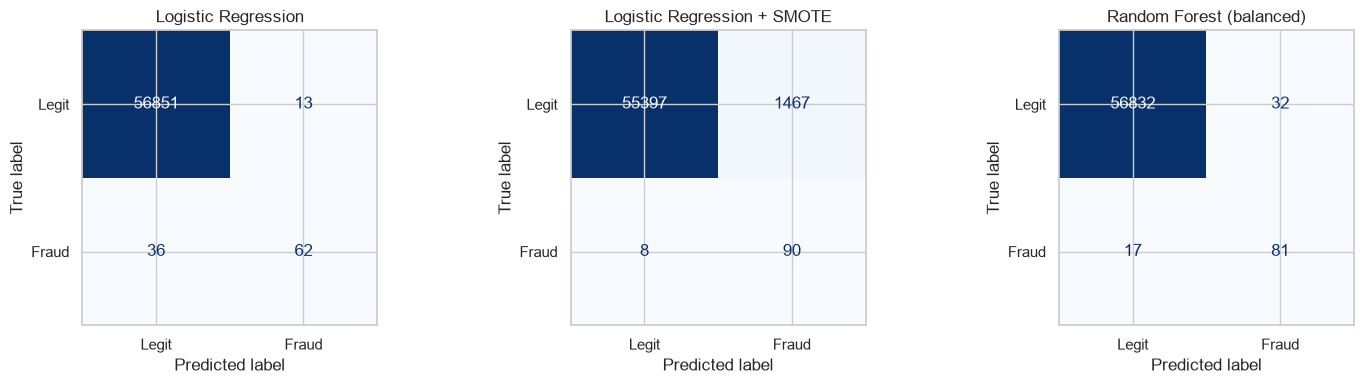

In [16]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,(name,pred) in zip(axes,predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=['Legit','Fraud'],
                                            cmap='Blues',colorbar=False,ax=ax)
    ax.set_title(name)
fig.tight_layout();fig.savefig(OUTPUT_DIR/'04_confusion_matrices.png',dpi=150);plt.show()

## 8. Precision–recall and ROC curves

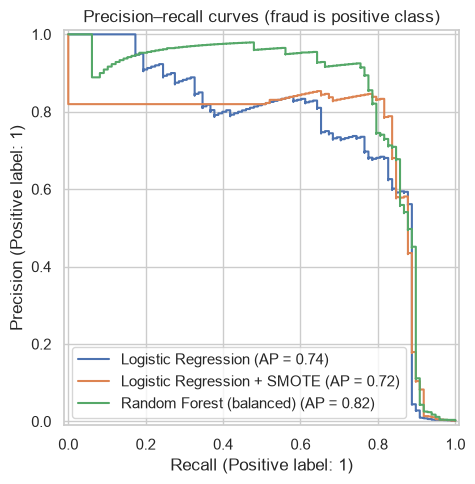

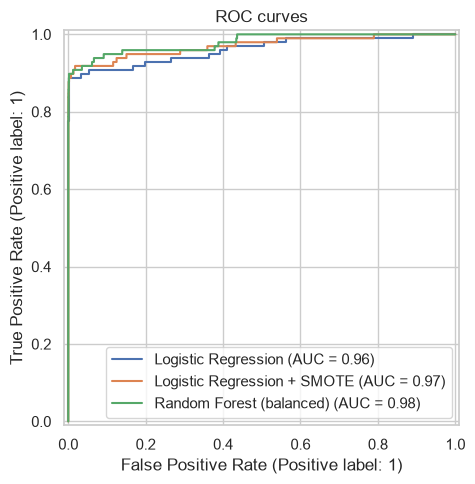

In [17]:
fig,ax=plt.subplots(figsize=(8,5))
for name,prob in probabilities.items():
    PrecisionRecallDisplay.from_predictions(y_test,prob,name=name,ax=ax)
ax.set_title('Precision–recall curves (fraud is positive class)')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'05_precision_recall.png',dpi=150);plt.show()
fig,ax=plt.subplots(figsize=(8,5))
for name,prob in probabilities.items():
    RocCurveDisplay.from_predictions(y_test,prob,name=name,ax=ax)
ax.set_title('ROC curves')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'06_roc_curves.png',dpi=150);plt.show()

## 9. Feature importance — Random Forest

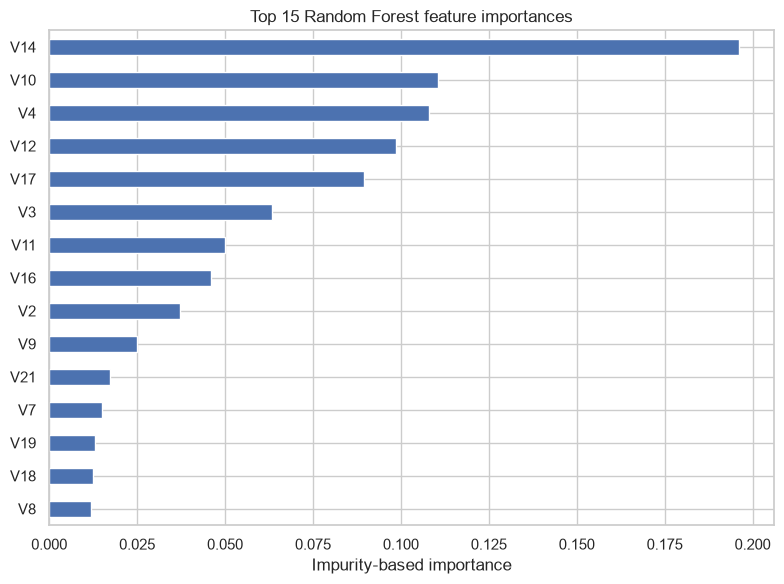

In [18]:
rf=models['Random Forest (balanced)']
importance=pd.Series(rf.feature_importances_,index=X_train.columns).sort_values().tail(15)
fig,ax=plt.subplots(figsize=(8,6))
importance.plot.barh(ax=ax)
ax.set(title='Top 15 Random Forest feature importances',xlabel='Impurity-based importance')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'07_feature_importance.png',dpi=150);plt.show()

## 10. Save model and predict one sample

Choose the model with highest *test-set F1* here for demonstration only. For a production workflow, select models and thresholds on validation data and reserve the test set for final evaluation. Do not load untrusted `.joblib` files.

In [19]:
best_name=results.iloc[0]['Model']
best_model=models[best_name]
joblib.dump(best_model,OUTPUT_DIR/'fraud_detection_model.joblib')
sample=X_test.iloc[[0]]
print('Saved model:',best_name)
print('Predicted class:',int(best_model.predict(sample)[0]))
print('Estimated fraud probability:',round(float(best_model.predict_proba(sample)[0,1]),5))
print('Actual class:',int(y_test.iloc[0]))

Saved model: Random Forest (balanced)
Predicted class: 0
Estimated fraud probability: 0.00136
Actual class: 0


## Interpretation and limitations

- **Accuracy is misleading** for rare fraud events: always inspect recall, precision, F1 and average precision.
- **SMOTE may increase recall but cause many false alarms**; compare precision and confusion matrices.
- Fraud detection has asymmetric costs; a threshold tuned on a separate validation set may outperform the default 0.5 threshold.
- The dataset is anonymized and historical; this is an educational demonstration, **not** a production payment-fraud system.
- Keep `creditcard.csv` out of GitHub; users can download it from Kaggle.
